# Bank Customer Churn — Modelling

**Objective:** identify the customers most likely to churn so retention can act first.

**Metric choice**

- **Recall is the primary metric.** A missed churner is a lost customer; the cost of an
  outreach email/call is small next to the revenue at risk. Recall answers "what share of the
  churners did we actually catch?".
- Recall alone is easy to game (flag everyone), so it is always reported with **precision**
  and the **share of customers flagged** — in practice you have a contact budget.
- **ROC-AUC** ranks customers and is used to pick the cut-off (Youden's J); **PR-AUC** is the
  more honest ranking summary at a ~20% positive rate, so the champion is chosen on OOF PR-AUC.
- Business KPI to track: **churners captured** at the operating threshold, not accuracy.

Pipeline: build + save the processed dataset → stratified split (seed 42) → three baselines
(SGD, RandomForest, XGBoost) with out-of-fold comparison → threshold from the ROC curve →
one final evaluation on the held-out test set → ranked at-risk customers.

## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from xgboost import XGBClassifier

%matplotlib inline
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "Churn_Modelling.csv"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_PATH = PROCESSED_DIR / "churn_processed.csv"

TARGET = "Exited"
ID_COLS = ["RowNumber", "CustomerId", "Surname"]
ENCODE_COLS = ["Geography", "Gender"]
SEED = 42
TEST_SIZE = 0.2


def section(title: str) -> None:
    print()
    print("=" * 78)
    print(title)
    print("=" * 78)


assert RAW_PATH.exists(), f"raw data not found at {RAW_PATH}"
print(f"raw data       : {RAW_PATH}")
print(f"processed data : {PROCESSED_PATH}")

raw data       : c:\Data Science Projects\Bank Churn Modelling\data\raw\Churn_Modelling.csv
processed data : c:\Data Science Projects\Bank Churn Modelling\data\processed\churn_processed.csv


## 1. Feature engineering and the processed dataset

- drop identifiers (`RowNumber`, `CustomerId`, `Surname`)
- add **`ZeroBalance`** = 1 when `Balance == 0` (36% of customers sit in this segment)
- **encode** the categoricals: `Geography` → one-hot (3 levels), `Gender` → one-hot (binary)
- save the model-ready frame to `data/processed/churn_processed.csv`

In [2]:
section("1. PROCESSED DATASET")
raw = pd.read_csv(RAW_PATH)

data = raw.drop(columns=ID_COLS).copy()
data["ZeroBalance"] = (data["Balance"] == 0).astype("int8")
data = pd.get_dummies(data, columns=ENCODE_COLS, prefix=["Geo", "Gender"], dtype="int8")

data = data[[c for c in data.columns if c != TARGET] + [TARGET]]   # target last

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
data.to_csv(PROCESSED_PATH, index=False)

print(f"saved {data.shape[0]:,} rows x {data.shape[1]} columns -> {PROCESSED_PATH.relative_to(PROJECT_ROOT)}")
print(f"features ({data.shape[1] - 1}): {[c for c in data.columns if c != TARGET]}")
print(f"encoded columns: {[c for c in data.columns if c.startswith(('Geo_', 'Gender_'))]}")
print(f"engineered     : ['ZeroBalance']")
print()
print(data.head(3).to_string(index=False))


1. PROCESSED DATASET
saved 10,000 rows x 15 columns -> data\processed\churn_processed.csv
features (14): ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'ZeroBalance', 'Geo_France', 'Geo_Germany', 'Geo_Spain', 'Gender_Female', 'Gender_Male']
encoded columns: ['Geo_France', 'Geo_Germany', 'Geo_Spain', 'Gender_Female', 'Gender_Male']
engineered     : ['ZeroBalance']

 CreditScore  Age  Tenure      Balance  NumOfProducts  HasCrCard  IsActiveMember  EstimatedSalary  ZeroBalance  Geo_France  Geo_Germany  Geo_Spain  Gender_Female  Gender_Male  Exited
         619   42       2       0.0000              1          1               1     101,348.8800            1           1            0          0              1            0       1
         608   41       1  83,807.8600              1          0               1     112,542.5800            0           0            0          1              1            0       0
         502   42  

## 2. Verify the saved artifact

In [3]:
section("2. VERIFY SAVED PROCESSED DATA")
processed = pd.read_csv(PROCESSED_PATH)

print(f"shape         : {processed.shape}")
print(f"missing cells : {int(processed.isna().sum().sum())}")
print(f"dtypes        : {processed.dtypes.astype(str).value_counts().to_dict()}")
print(f"target        : '{TARGET}' -> churn rate {processed[TARGET].mean():.2%}")
print(f"ZeroBalance   : {processed['ZeroBalance'].mean():.2%} of customers, "
      f"churn rate {processed.loc[processed['ZeroBalance'] == 1, TARGET].mean():.2%} "
      f"(vs {processed.loc[processed['ZeroBalance'] == 0, TARGET].mean():.2%} for balance > 0)")
print(f"non-numeric columns left: {processed.select_dtypes(exclude='number').columns.tolist() or 'none'}")


2. VERIFY SAVED PROCESSED DATA
shape         : (10000, 15)
missing cells : 0
dtypes        : {'int64': 13, 'float64': 2}
target        : 'Exited' -> churn rate 20.37%
ZeroBalance   : 36.17% of customers, churn rate 13.82% (vs 24.08% for balance > 0)
non-numeric columns left: none


## 3. Stratified train/test split

Same protocol as the EDA: 80/20, stratified on the target, `random_state=42`.
The test set is scored exactly once, at the end.

In [4]:
section("3. STRATIFIED TRAIN/TEST SPLIT")
X = processed.drop(columns=[TARGET])
y = processed[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y
)

split = pd.DataFrame({
    "rows": [len(y), len(y_train), len(y_test)],
    "churn_%": [y.mean() * 100, y_train.mean() * 100, y_test.mean() * 100],
    "churned": [int(y.sum()), int(y_train.sum()), int(y_test.sum())],
}, index=["full", "train", "test"]).round(3)
print(split)
print()
print(f"X_train {X_train.shape} | X_test {X_test.shape}")
print(f"stratification gap: {abs(y_train.mean() - y_test.mean()) * 100:.3f} percentage points")


3. STRATIFIED TRAIN/TEST SPLIT
        rows  churn_%  churned
full   10000  20.3700     2037
train   8000  20.3750     1630
test    2000  20.3500      407

X_train (8000, 14) | X_test (2000, 14)
stratification gap: 0.025 percentage points


## 4. Baseline models

All three handle the 20/80 imbalance internally, so no resampling is needed for a first pass:

| model | imbalance handling |
|---|---|
| SGD (`loss="log_loss"`) | `class_weight="balanced"` + `StandardScaler` |
| RandomForest | `class_weight="balanced_subsample"` |
| XGBoost | `scale_pos_weight = negatives / positives` |

In [ ]:
section("4. BASELINE MODELS & METRIC HELPERS")
scale_pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())
print(f"scale_pos_weight (negatives / positives) = {scale_pos_weight:.3f}")


def make_models() -> dict:
    """Fresh unfitted baselines, so every fold and fit starts from scratch."""
    return {
        "SGD (log_loss, balanced)": Pipeline([
            ("scale", StandardScaler()),
            ("clf", SGDClassifier(loss="log_loss", penalty="l2", alpha=1e-4,
                                  class_weight="balanced", max_iter=3000, tol=1e-4,
                                  random_state=SEED)),
        ]),
        "RandomForest (balanced_subsample)": RandomForestClassifier(
            n_estimators=400, min_samples_leaf=5, class_weight="balanced_subsample",
            random_state=SEED, n_jobs=-1),
        "XGBoost (scale_pos_weight)": XGBClassifier(
            n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.9,
            colsample_bytree=0.9, scale_pos_weight=scale_pos_weight,
            random_state=SEED, n_jobs=-1),
    }


def metrics_at(y_true, proba, threshold: float) -> dict:
    """Classification metrics for one probability cut-off."""
    pred = (proba >= threshold).astype(int)
    return {
        "threshold": float(np.round(float(threshold), 3)),
        "flagged_%": float(np.round(pred.mean() * 100, 2)),
        "recall": float(np.round(recall_score(y_true, pred, zero_division=0), 4)),
        "precision": float(np.round(precision_score(y_true, pred, zero_division=0), 4)),
        "f1": float(np.round(f1_score(y_true, pred, zero_division=0), 4)),
    }


def youden_cutoff(y_true, proba):
    """Threshold maximising TPR - FPR (Youden's J) on the ROC curve."""
    fpr, tpr, thresholds = roc_curve(y_true, proba)
    best = int(np.argmax(tpr - fpr))
    return float(thresholds[best]), float(tpr[best]), float(fpr[best])


print(list(make_models()))


4. BASELINE MODELS & METRIC HELPERS
scale_pos_weight (negatives / positives) = 3.908
['SGD (log_loss, balanced)', 'RandomForest (balanced_subsample)', 'XGBoost (scale_pos_weight)']


## 5. Cross-validated comparison

5-fold **stratified** CV on the training set only. Each row's prediction comes from a model
that never saw that row (out-of-fold), so the comparison is honest and the OOF probabilities
can be used to choose the threshold.

In [6]:
section("5. OUT-OF-FOLD COMPARISON (StratifiedKFold, 5 folds, seed 42)")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof, ranking, detail = {}, [], []

for name, model in make_models().items():
    probs = np.zeros(len(y_train))
    for tr_idx, va_idx in cv.split(X_train, y_train):
        fitted = clone(model).fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        probs[va_idx] = fitted.predict_proba(X_train.iloc[va_idx])[:, 1]
    oof[name] = probs

    thr, tpr, fpr = youden_cutoff(y_train, probs)
    ranking.append({
        "model": name,
        "roc_auc": roc_auc_score(y_train, probs),
        "pr_auc": average_precision_score(y_train, probs),
        "youden_threshold": thr,
        "youden_recall": tpr,
        "youden_fpr": fpr,
    })
    for label, t in (("0.50", 0.50), ("youden", thr)):
        row = metrics_at(y_train, probs, t)
        row.update({"model": name, "rule": label})
        detail.append(row)

ranking_df = pd.DataFrame(ranking).set_index("model").sort_values("pr_auc", ascending=False).round(4)
print("ranking by out-of-fold PR-AUC:")
print(ranking_df.to_string())

detail_df = (pd.DataFrame(detail)[["model", "rule", "threshold", "flagged_%", "recall", "precision", "f1"]]
             .sort_values(["model", "rule"]))
print()
print("default 0.50 cut-off vs Youden cut-off:")
print(detail_df.to_string(index=False))

CHAMPION = ranking_df.index[0]
print()
print(f"champion by OOF PR-AUC: {CHAMPION}")


5. OUT-OF-FOLD COMPARISON (StratifiedKFold, 5 folds, seed 42)
ranking by out-of-fold PR-AUC:
                                   roc_auc  pr_auc  youden_threshold  youden_recall  youden_fpr
model                                                                                          
XGBoost (scale_pos_weight)          0.8616  0.6964            0.4508         0.7540      0.1931
RandomForest (balanced_subsample)   0.8577  0.6653            0.4010         0.7350      0.1816
SGD (log_loss, balanced)            0.7250  0.4244            0.5429         0.6018      0.2444

default 0.50 cut-off vs Youden cut-off:
                            model   rule  threshold  flagged_%  recall  precision     f1
RandomForest (balanced_subsample)   0.50     0.5000    21.4400  0.6319     0.6006 0.6158
RandomForest (balanced_subsample) youden     0.4010    29.4400  0.7350     0.5087 0.6013
         SGD (log_loss, balanced)   0.50     0.5000    36.8500  0.6491     0.3589 0.4622
         SGD (log_loss, balan

## 6. Threshold from the ROC curve

Recall is the metric we optimise, but it cannot be maximised alone — a threshold of 0 would
flag everybody. The cut-off comes from the ROC curve (Youden's J), then the
precision/recall trade-off is inspected so the operating point can be moved by contact budget.


6. THRESHOLD SELECTION - XGBoost (scale_pos_weight)


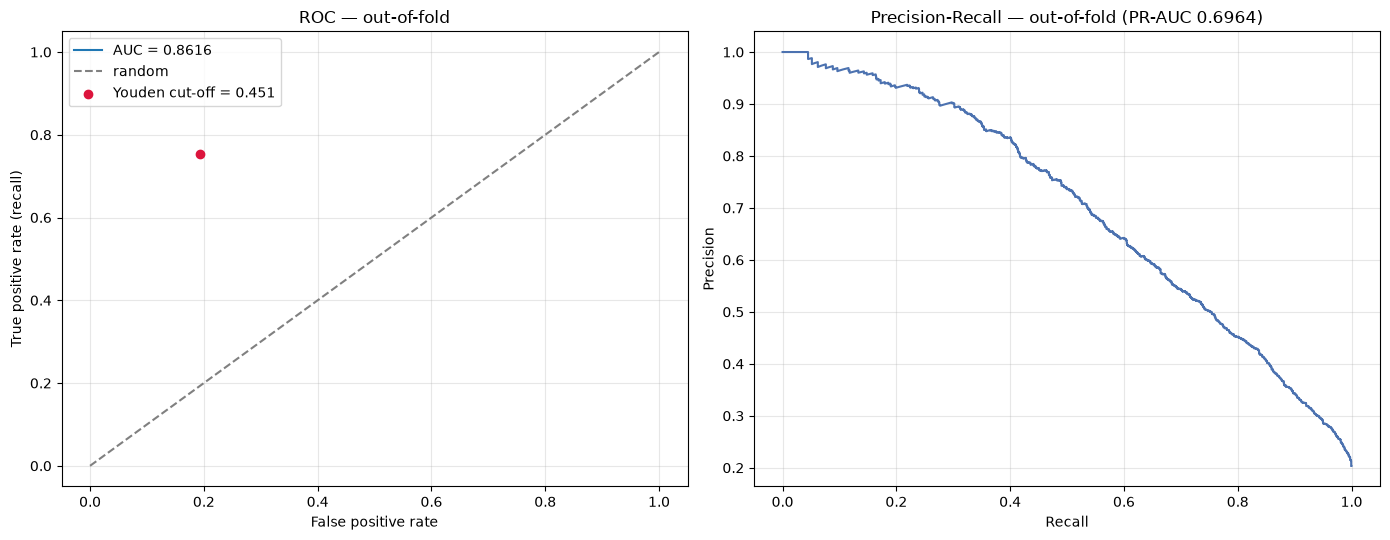

recall / precision trade-off on out-of-fold scores:
 threshold  flagged_%  recall  precision     f1
    0.1000    74.3400  0.9712     0.2662 0.4178
    0.1500    63.6500  0.9393     0.3007 0.4555
    0.2000    55.6600  0.9080     0.3324 0.4866
    0.2500    48.6800  0.8779     0.3675 0.5181
    0.3000    43.1000  0.8515     0.4026 0.5467
    0.3500    38.5900  0.8233     0.4347 0.5690
    0.4000    34.2400  0.7816     0.4651 0.5832
    0.4500    30.7900  0.7540     0.4990 0.6005
    0.5000    27.4900  0.7160     0.5307 0.6096
    0.6000    21.5900  0.6374     0.6016 0.6190

Youden cut-off: 0.451 -> recall 0.754, precision 0.500, 30.7% of customers flagged
recall >= 80% costs threshold 0.377 (precision 0.452, recall 0.801, 36.1% flagged)
recall >= 75% costs threshold 0.454 (precision 0.502, recall 0.750, 30.4% flagged)
recall >= 70% costs threshold 0.520 (precision 0.544, recall 0.700, 26.2% flagged)

operating threshold for the final model: 0.451


In [7]:
section(f"6. THRESHOLD SELECTION - {CHAMPION}")
probs_oof = oof[CHAMPION]
threshold_flag, tpr_at, fpr_at = youden_cutoff(y_train, probs_oof)
prec, rec, pr_thr = precision_recall_curve(y_train, probs_oof)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_train, probs_oof):.4f}")
axes[0].plot([0, 1], [0, 1], "--", color="grey", label="random")
axes[0].scatter([fpr_at], [tpr_at], color="crimson", zorder=5,
                label=f"Youden cut-off = {threshold_flag:.3f}")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC — out-of-fold")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(rec, prec, color="#4C72B0")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title(f"Precision-Recall — out-of-fold (PR-AUC {average_precision_score(y_train, probs_oof):.4f})")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

grid = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60]
tradeoff = pd.DataFrame([metrics_at(y_train, probs_oof, t) for t in grid])
print("recall / precision trade-off on out-of-fold scores:")
print(tradeoff.to_string(index=False))

print()
print(f"Youden cut-off: {threshold_flag:.3f} -> recall {tpr_at:.3f}, precision "
      f"{precision_score(y_train, (probs_oof >= threshold_flag).astype(int)):.3f}, "
      f"{((probs_oof >= threshold_flag).mean() * 100):.1f}% of customers flagged")

for target_recall in (0.80, 0.75, 0.70):
    ok = rec >= target_recall
    if ok.any():
        idx = int(np.argmax(np.where(ok, prec, -1)))
        thr = float(pr_thr[min(idx, len(pr_thr) - 1)])
        print(f"recall >= {target_recall:.0%} costs threshold {thr:.3f} "
              f"(precision {prec[idx]:.3f}, recall {rec[idx]:.3f}, "
              f"{((probs_oof >= thr).mean() * 100):.1f}% flagged)")

THRESHOLD = threshold_flag
print()
print(f"operating threshold for the final model: {THRESHOLD:.3f}")

## 7. Final evaluation on the held-out test set

The champion is refit on all 8,000 training rows and scored **once** on the 2,000 test rows —
no further tuning on the test set, so the numbers are an unbiased estimate.


7. FINAL MODEL - HELD-OUT TEST SET
test ROC-AUC : 0.8620
test PR-AUC  : 0.7056

operating_point  threshold  flagged_%  recall  precision     f1
 0.50 (default)     0.5000    28.9000  0.7346     0.5173 0.6071
 0.451 (Youden)     0.4510    32.3500  0.7740     0.4869 0.5977

confusion matrix at the operating threshold:
                 pred: stayed  pred: churned
actual: stayed           1261            332
actual: churned            92            315

              precision    recall  f1-score   support

  stayed (0)      0.932     0.792     0.856      1593
 churned (1)      0.487     0.774     0.598       407

    accuracy                          0.788      2000
   macro avg      0.709     0.783     0.727      2000
weighted avg      0.841     0.788     0.804      2000



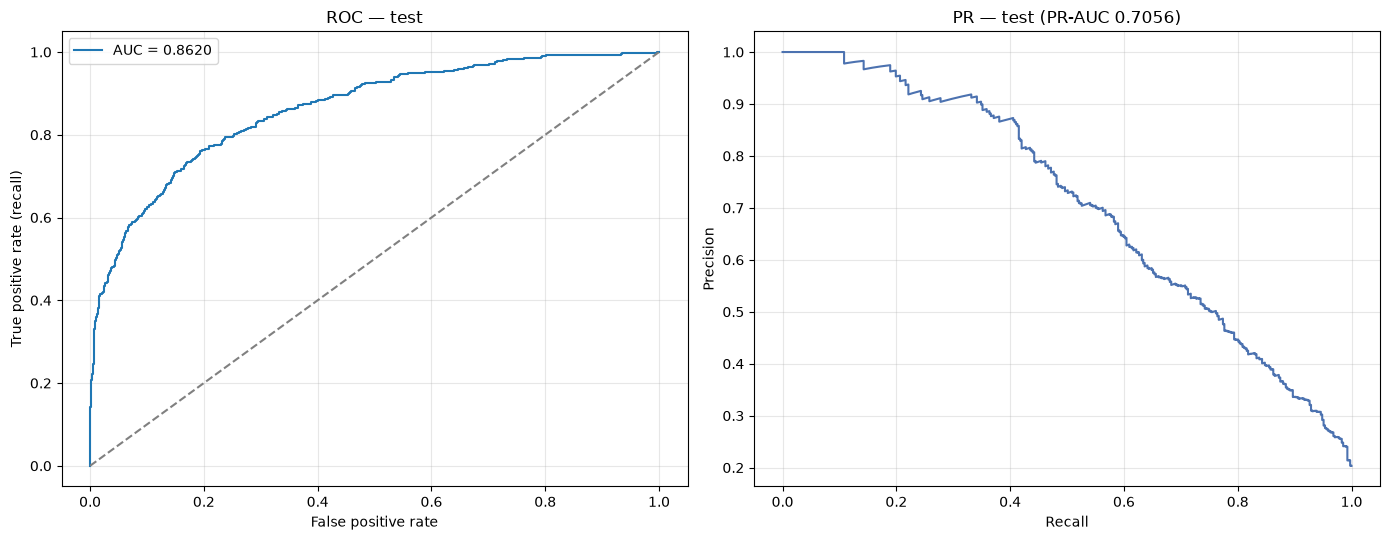

In [8]:
section("7. FINAL MODEL - HELD-OUT TEST SET")
final_model = make_models()[CHAMPION]
final_model.fit(X_train, y_train)
test_proba = final_model.predict_proba(X_test)[:, 1]

print(f"test ROC-AUC : {roc_auc_score(y_test, test_proba):.4f}")
print(f"test PR-AUC  : {average_precision_score(y_test, test_proba):.4f}")
print()

comparison = pd.DataFrame([
    {"operating_point": "0.50 (default)", **metrics_at(y_test, test_proba, 0.50)},
    {"operating_point": f"{THRESHOLD:.3f} (Youden)", **metrics_at(y_test, test_proba, THRESHOLD)},
])
print(comparison.to_string(index=False))
print()

test_pred = (test_proba >= THRESHOLD).astype(int)
print("confusion matrix at the operating threshold:")
print(pd.DataFrame(confusion_matrix(y_test, test_pred, labels=[0, 1]),
                   index=["actual: stayed", "actual: churned"],
                   columns=["pred: stayed", "pred: churned"]))
print()
print(classification_report(y_test, test_pred, digits=3,
                            target_names=["stayed (0)", "churned (1)"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
fpr_t, tpr_t, _ = roc_curve(y_test, test_proba)
axes[0].plot(fpr_t, tpr_t, label=f"AUC = {roc_auc_score(y_test, test_proba):.4f}")
axes[0].plot([0, 1], [0, 1], "--", color="grey")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC — test")
axes[0].legend()
axes[0].grid(alpha=0.3)

prec_t, rec_t, _ = precision_recall_curve(y_test, test_proba)
axes[1].plot(rec_t, prec_t, color="#4C72B0")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title(f"PR — test (PR-AUC {average_precision_score(y_test, test_proba):.4f})")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. What drives churn


8. FEATURE IMPORTANCE (fitted on the training set)
                 RandomForest  XGBoost
NumOfProducts          0.1689   0.2269
IsActiveMember         0.0475   0.1284
Age                    0.3008   0.1176
ZeroBalance            0.0191   0.1116
Geo_Germany            0.0346   0.0955
Gender_Female          0.0138   0.0584
Balance                0.1119   0.0437
Gender_Male            0.0130   0.0435
Geo_France             0.0150   0.0415
Geo_Spain              0.0103   0.0332
Tenure                 0.0598   0.0270
CreditScore            0.0945   0.0268
EstimatedSalary        0.0976   0.0265
HasCrCard              0.0131   0.0195


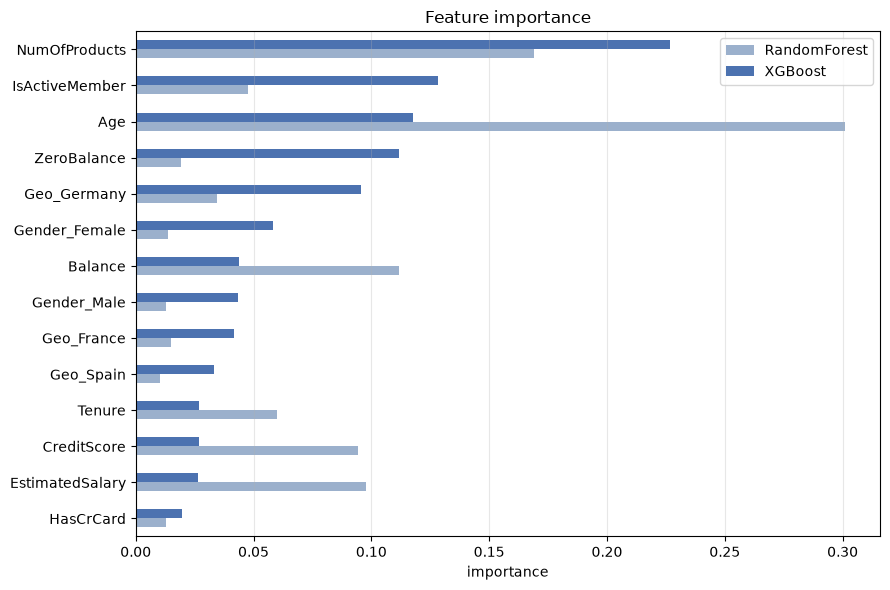

note: these are impurity/gain importances — direction of effect is not encoded, so read them together with the EDA means (older customers, higher balance, Germany, female, 3+ products churn more)


In [9]:
section("8. FEATURE IMPORTANCE (fitted on the training set)")
rf = RandomForestClassifier(n_estimators=400, min_samples_leaf=5,
                            class_weight="balanced_subsample",
                            random_state=SEED, n_jobs=-1).fit(X_train, y_train)
xgb = XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.9,
                    colsample_bytree=0.9, scale_pos_weight=scale_pos_weight,
                    random_state=SEED, n_jobs=-1).fit(X_train, y_train)

importance = pd.DataFrame({
    "RandomForest": rf.feature_importances_,
    "XGBoost": xgb.feature_importances_,
}, index=X_train.columns).sort_values("XGBoost", ascending=False)
print(importance.round(4).to_string())

fig, ax = plt.subplots(figsize=(9, 6))
importance.sort_values("XGBoost").plot.barh(ax=ax, color=["#9BB0CC", "#4C72B0"])
ax.set_title("Feature importance")
ax.set_xlabel("importance")
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

print("note: these are impurity/gain importances — direction of effect is not encoded, "
      "so read them together with the EDA means (older customers, higher balance, "
      "Germany, female, 3+ products churn more)")

## 9. Customers most likely to churn

Scoring the 2,000 held-out customers — the closest available proxy for customers the bank has
not been able to flag yet. Each row carries its real churn outcome, which lets the risk bands
be validated rather than trusted.

In [10]:
section("9. AT-RISK CUSTOMERS (held-out, ranked by predicted probability)")
scored = raw.loc[X_test.index, ["CustomerId", "Surname", "Geography", "Gender", "Age",
                                "Balance", "NumOfProducts", "IsActiveMember"]].copy()
scored["churn_probability"] = test_proba
scored["flagged"] = (test_proba >= THRESHOLD).astype(int)
scored["actual"] = y_test.loc[scored.index]
scored["risk_band"] = pd.cut(scored["churn_probability"], bins=[-0.001, 0.20, 0.50, 1.0],
                             labels=["low (<0.20)", "medium (0.20-0.50)", "high (>=0.50)"])
scored = scored.sort_values("churn_probability", ascending=False)

bands = (scored.groupby("risk_band", observed=True)
         .agg(customers=("CustomerId", "size"), mean_score=("churn_probability", "mean"),
              actual_churn_rate=("actual", "mean")))
bands["share_%"] = (bands["customers"] / len(scored) * 100).round(2)
bands["actual_churn_%"] = (bands["actual_churn_rate"] * 100).round(2)
print("risk bands:")
print(bands[["customers", "share_%", "mean_score", "actual_churn_%"]].round(3).to_string())

scored["decile"] = pd.qcut(scored["churn_probability"].rank(method="first"), 10, labels=False) + 1
deciles = (scored.groupby("decile")
           .agg(customers=("CustomerId", "size"), churners=("actual", "sum"),
                churn_rate=("actual", "mean"))
           .sort_index(ascending=False))
deciles["churn_rate_%"] = (deciles["churn_rate"] * 100).round(1)
deciles["churners_captured_%"] = (deciles["churners"].cumsum() / scored["actual"].sum() * 100).round(1)
print()
print("deciles by score (10 = highest risk):")
print(deciles[["customers", "churners", "churn_rate_%", "churners_captured_%"]].to_string())

top = 50
top_share = scored.head(top)["actual"].mean()
print()
print(f"top {top} customers ({top / len(scored):.1%} of the test set): "
      f"{int(scored.head(top)['actual'].sum())} real churners, actual churn rate {top_share:.1%} "
      f"vs {scored['actual'].mean():.1%} overall "
      f"({top_share / scored['actual'].mean():.1f}x lift)")
print()
print(f"top 15 of {len(scored):,} customers to contact first:")
print(scored.head(15)[["CustomerId", "Surname", "Geography", "Gender", "Age", "Balance",
                       "NumOfProducts", "IsActiveMember", "churn_probability"]]
      .round({"churn_probability": 3}).to_string(index=False))


9. AT-RISK CUSTOMERS (held-out, ranked by predicted probability)
risk bands:
                    customers  share_%  mean_score  actual_churn_%
risk_band                                                         
low (<0.20)               854  42.7000      0.0930          3.5100
medium (0.20-0.50)        568  28.4000      0.3350         13.7300
high (>=0.50)             578  28.9000      0.7460         51.7300

deciles by score (10 = highest risk):
        customers  churners  churn_rate_%  churners_captured_%
decile                                                        
10            200       169       84.5000              41.5000
9             200        81       40.5000              61.4000
8             200        54       27.0000              74.7000
7             200        31       15.5000              82.3000
6             200        25       12.5000              88.5000
5             200        18        9.0000              92.9000
4             200        10        5.0000   

## 10. Summary

In [ ]:
section("10. SUMMARY")
print(f"processed data : {PROCESSED_PATH.relative_to(PROJECT_ROOT)} "
      f"({processed.shape[0]:,} x {processed.shape[1]})")
print(f"split          : {len(X_train):,} train / {len(X_test):,} test, stratified, seed {SEED}")
print(f"champion       : {CHAMPION} (OOF PR-AUC {ranking_df.loc[CHAMPION, 'pr_auc']:.4f}, "
      f"OOF ROC-AUC {ranking_df.loc[CHAMPION, 'roc_auc']:.4f})")
print(f"test           : ROC-AUC {roc_auc_score(y_test, test_proba):.4f}, "
      f"PR-AUC {average_precision_score(y_test, test_proba):.4f}")
print(f"operating point: threshold {THRESHOLD:.3f} -> recall "
      f"{metrics_at(y_test, test_proba, THRESHOLD)['recall']:.3f}, precision "
      f"{metrics_at(y_test, test_proba, THRESHOLD)['precision']:.3f}, "
      f"{metrics_at(y_test, test_proba, THRESHOLD)['flagged_%']:.1f}% flagged")
print()
print("next steps: tune the champion (grid search on PR-AUC), compare against SMOTE /")
print("threshold-per-budget policies, and score the live customer base to drive retention.")


10. SUMMARY
processed data : data\processed\churn_processed.csv (10,000 x 15)
split          : 8,000 train / 2,000 test, stratified, seed 42
champion       : XGBoost (scale_pos_weight) (OOF PR-AUC 0.6964, OOF ROC-AUC 0.8616)
test           : ROC-AUC 0.8620, PR-AUC 0.7056
operating point: threshold 0.451 -> recall 0.774, precision 0.487, 32.4% flagged

next steps: tune the champion (grid search on PR-AUC), compare against SMOTE /
threshold-per-budget policies, and score the live customer base to drive retention.


: 